# Final benchmark results explorer

This notebook reads the single retained four-policy result set in `research/results/final/`. It covers 12 network/capacity configurations at 50 tasks and 30 repetitions. RTT values are simulated and workers share one physical host.

In [10]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

# Locate the repository root whether Jupyter starts there or in research/.
candidates = [Path.cwd(), Path.cwd() / 'research', Path.cwd().parent]
RESEARCH = next((p.resolve() for p in candidates if (p / 'results' / 'final' / 'raw').is_dir()), None)
if RESEARCH is None:
    raise FileNotFoundError('Could not find research/results/final/raw; open this notebook from the repository or research folder.')
BENCHMARK_RESULTS = RESEARCH / 'results' / 'final'
raw_files = sorted((BENCHMARK_RESULTS / 'raw').glob('*.json'))
print(f'Final experiment exports: {len(raw_files)}')


Final experiment exports: 12


In [13]:
records = []
for path in raw_files:
    payload = json.loads(path.read_text(encoding='utf-8'))
    experiment = payload.get('experiment', {})
    configuration = experiment.get('configuration', {})
    scenario = configuration.get('scenario') or {}
    for result in payload.get('results', []):
        metrics = result.get('metrics') or {}
        if metrics.get('resultType') != 'task':
            continue
        records.append({
            'experiment_id': experiment.get('id'),
            'algorithm': result.get('algorithm'),
            'status': metrics.get('status', 'unknown'),
            'response_ms': metrics.get('actualResponseMs'),
            'repetition': result.get('repetition'),
            'worker': result.get('nodeId') or 'unassigned',
            'network_profile': scenario.get('networkProfile', 'unknown'),
            'capacity_profile': scenario.get('capacityProfile', 'unknown'),
            'task_count': scenario.get('taskCount', configuration.get('taskCount')),
        })
tasks = pd.DataFrame(records)
if tasks.empty:
    raise ValueError('The exports contain no task-level records.')
successful = tasks[(tasks['status'] == 'succeeded') & tasks['response_ms'].notna()].copy()
summary = tasks.groupby('algorithm').agg(
    task_records=('status', 'size'),
    succeeded=('status', lambda s: (s == 'succeeded').sum()),
    success_rate=('status', lambda s: (s == 'succeeded').mean()),
).join(successful.groupby('algorithm')['response_ms'].agg(['mean', 'median']))
summary

,task_records,succeeded,success_rate,mean,median
algorithm,,,,,
edge-only,18000,18000,1.0,28.396442,24.853903
fewest-active-tasks,18000,18000,1.0,49.016579,41.853138
latency-aware,18000,18000,1.0,30.256119,27.492789
round-robin,18000,18000,1.0,48.954838,41.770504


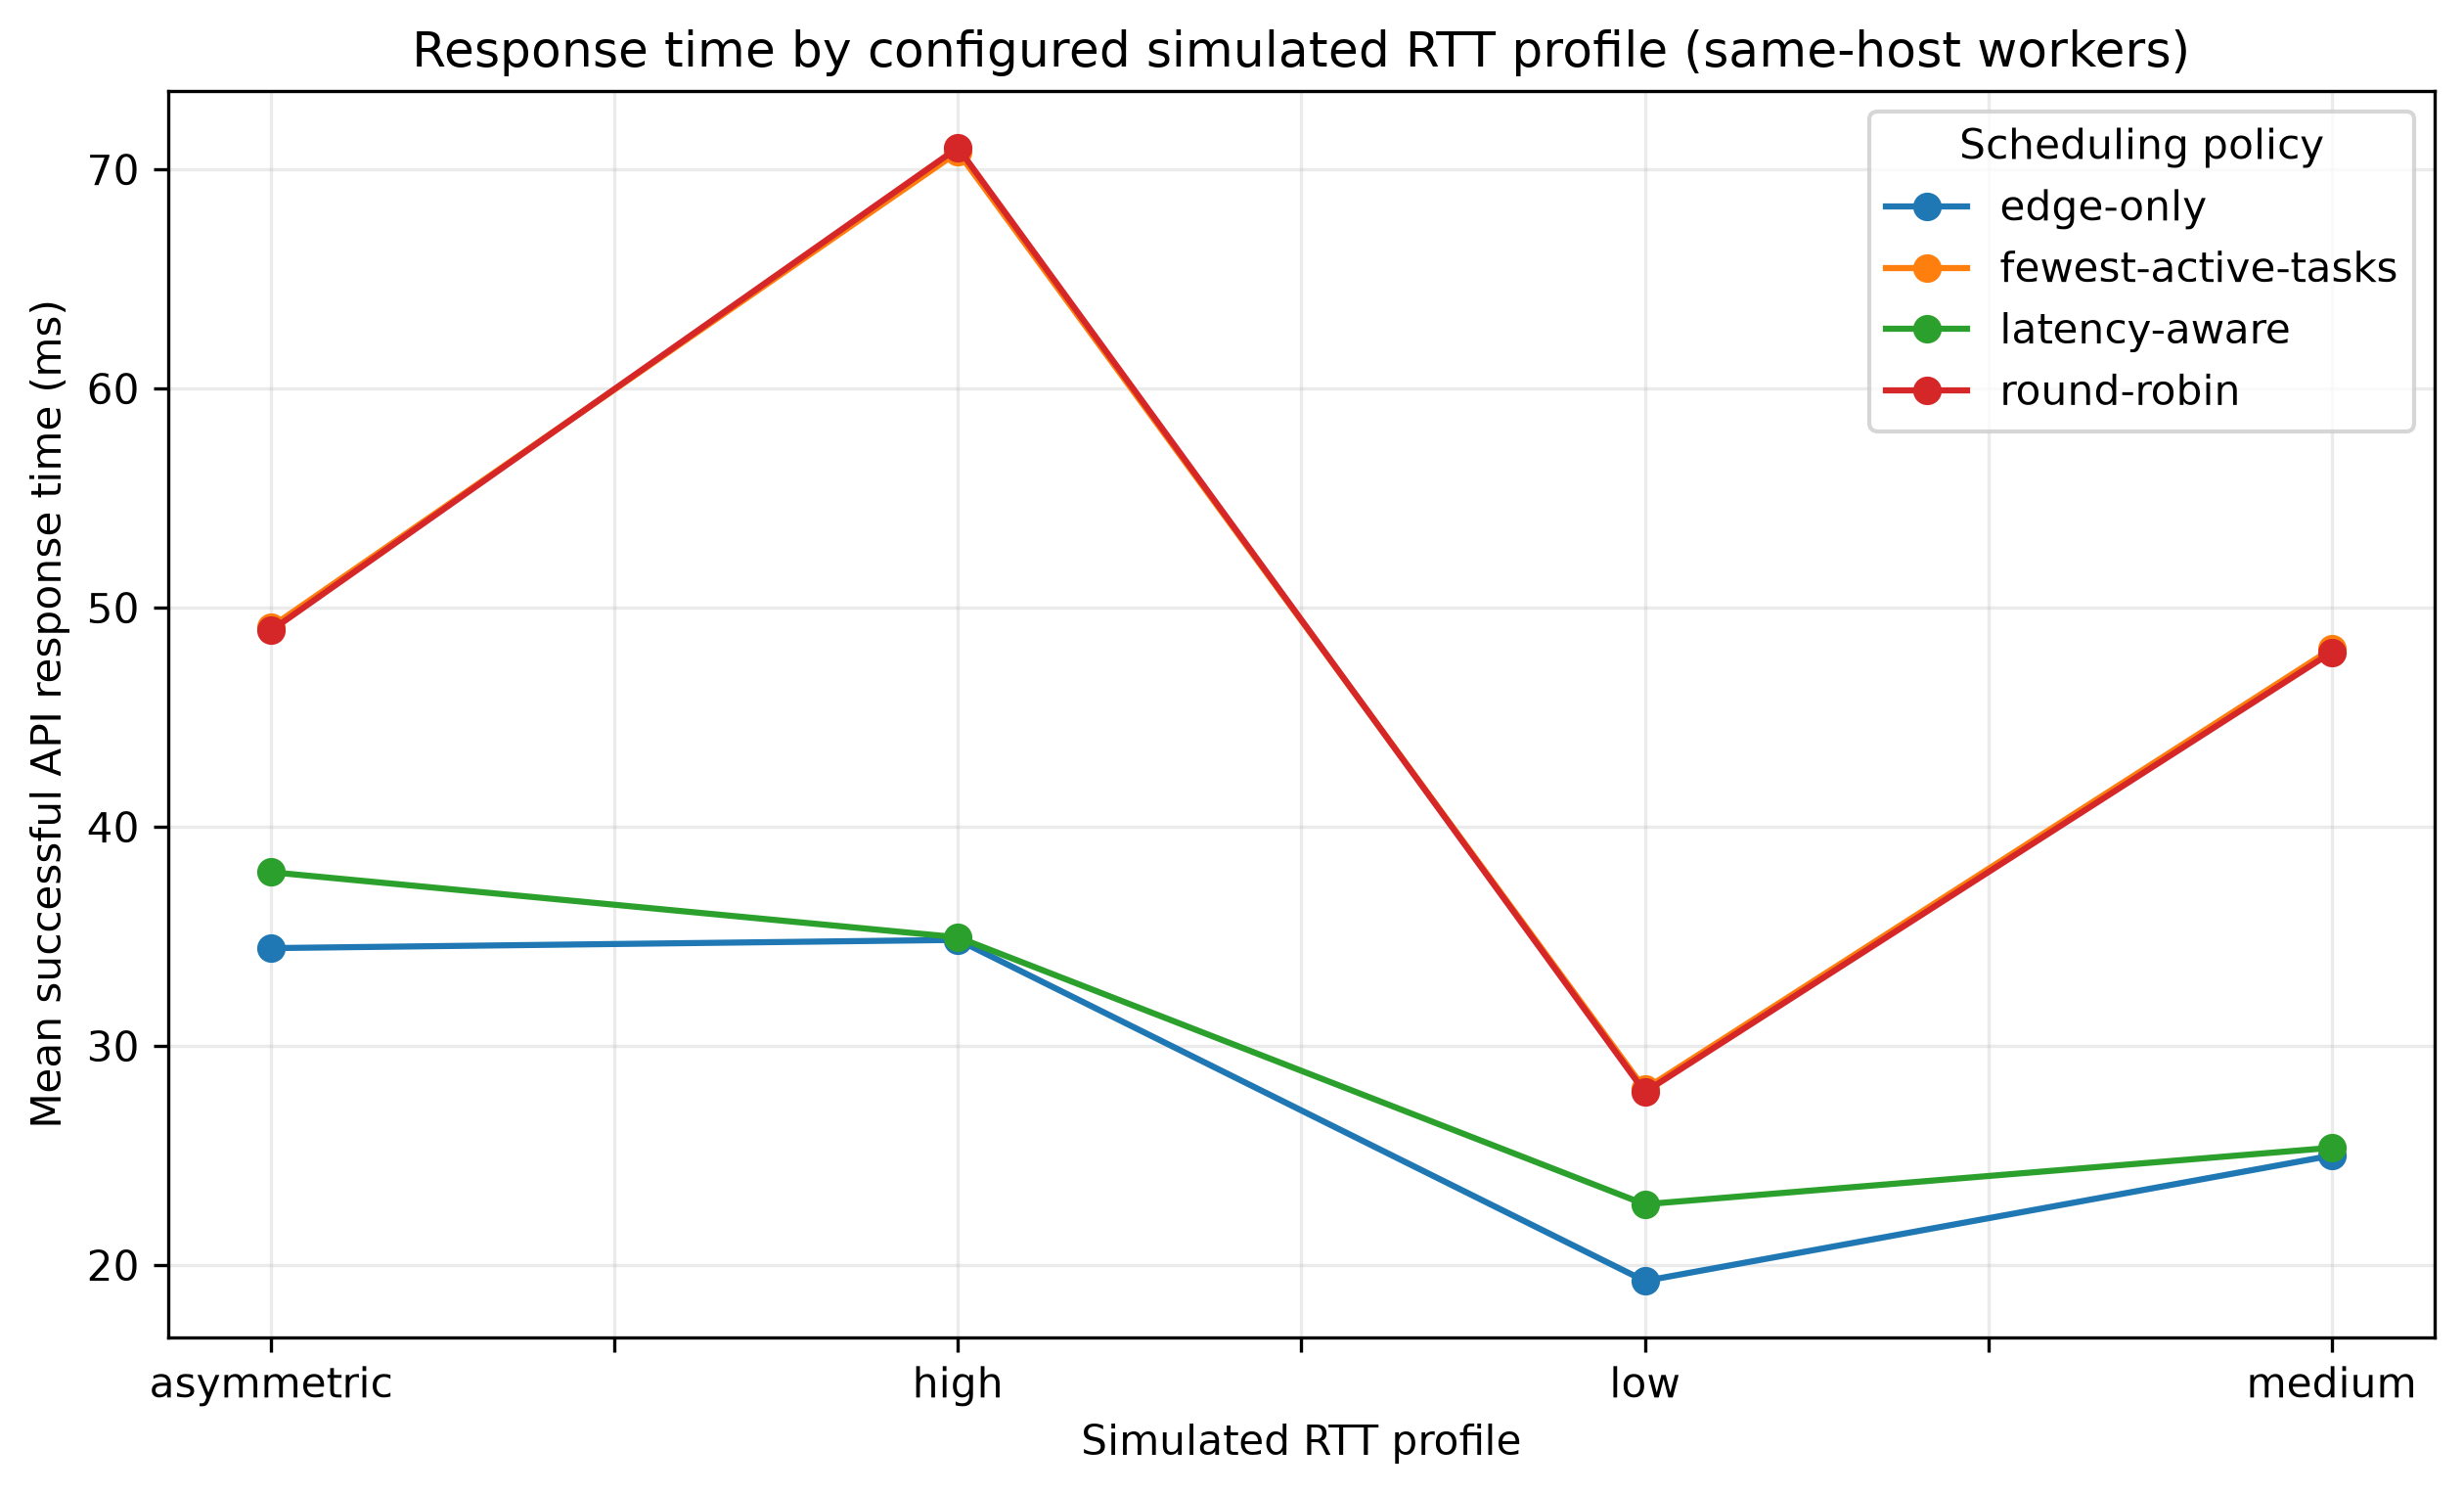

In [11]:
display(Image(filename=str(BENCHMARK_RESULTS / 'graphs' / 'performance_by_rtt.png')))


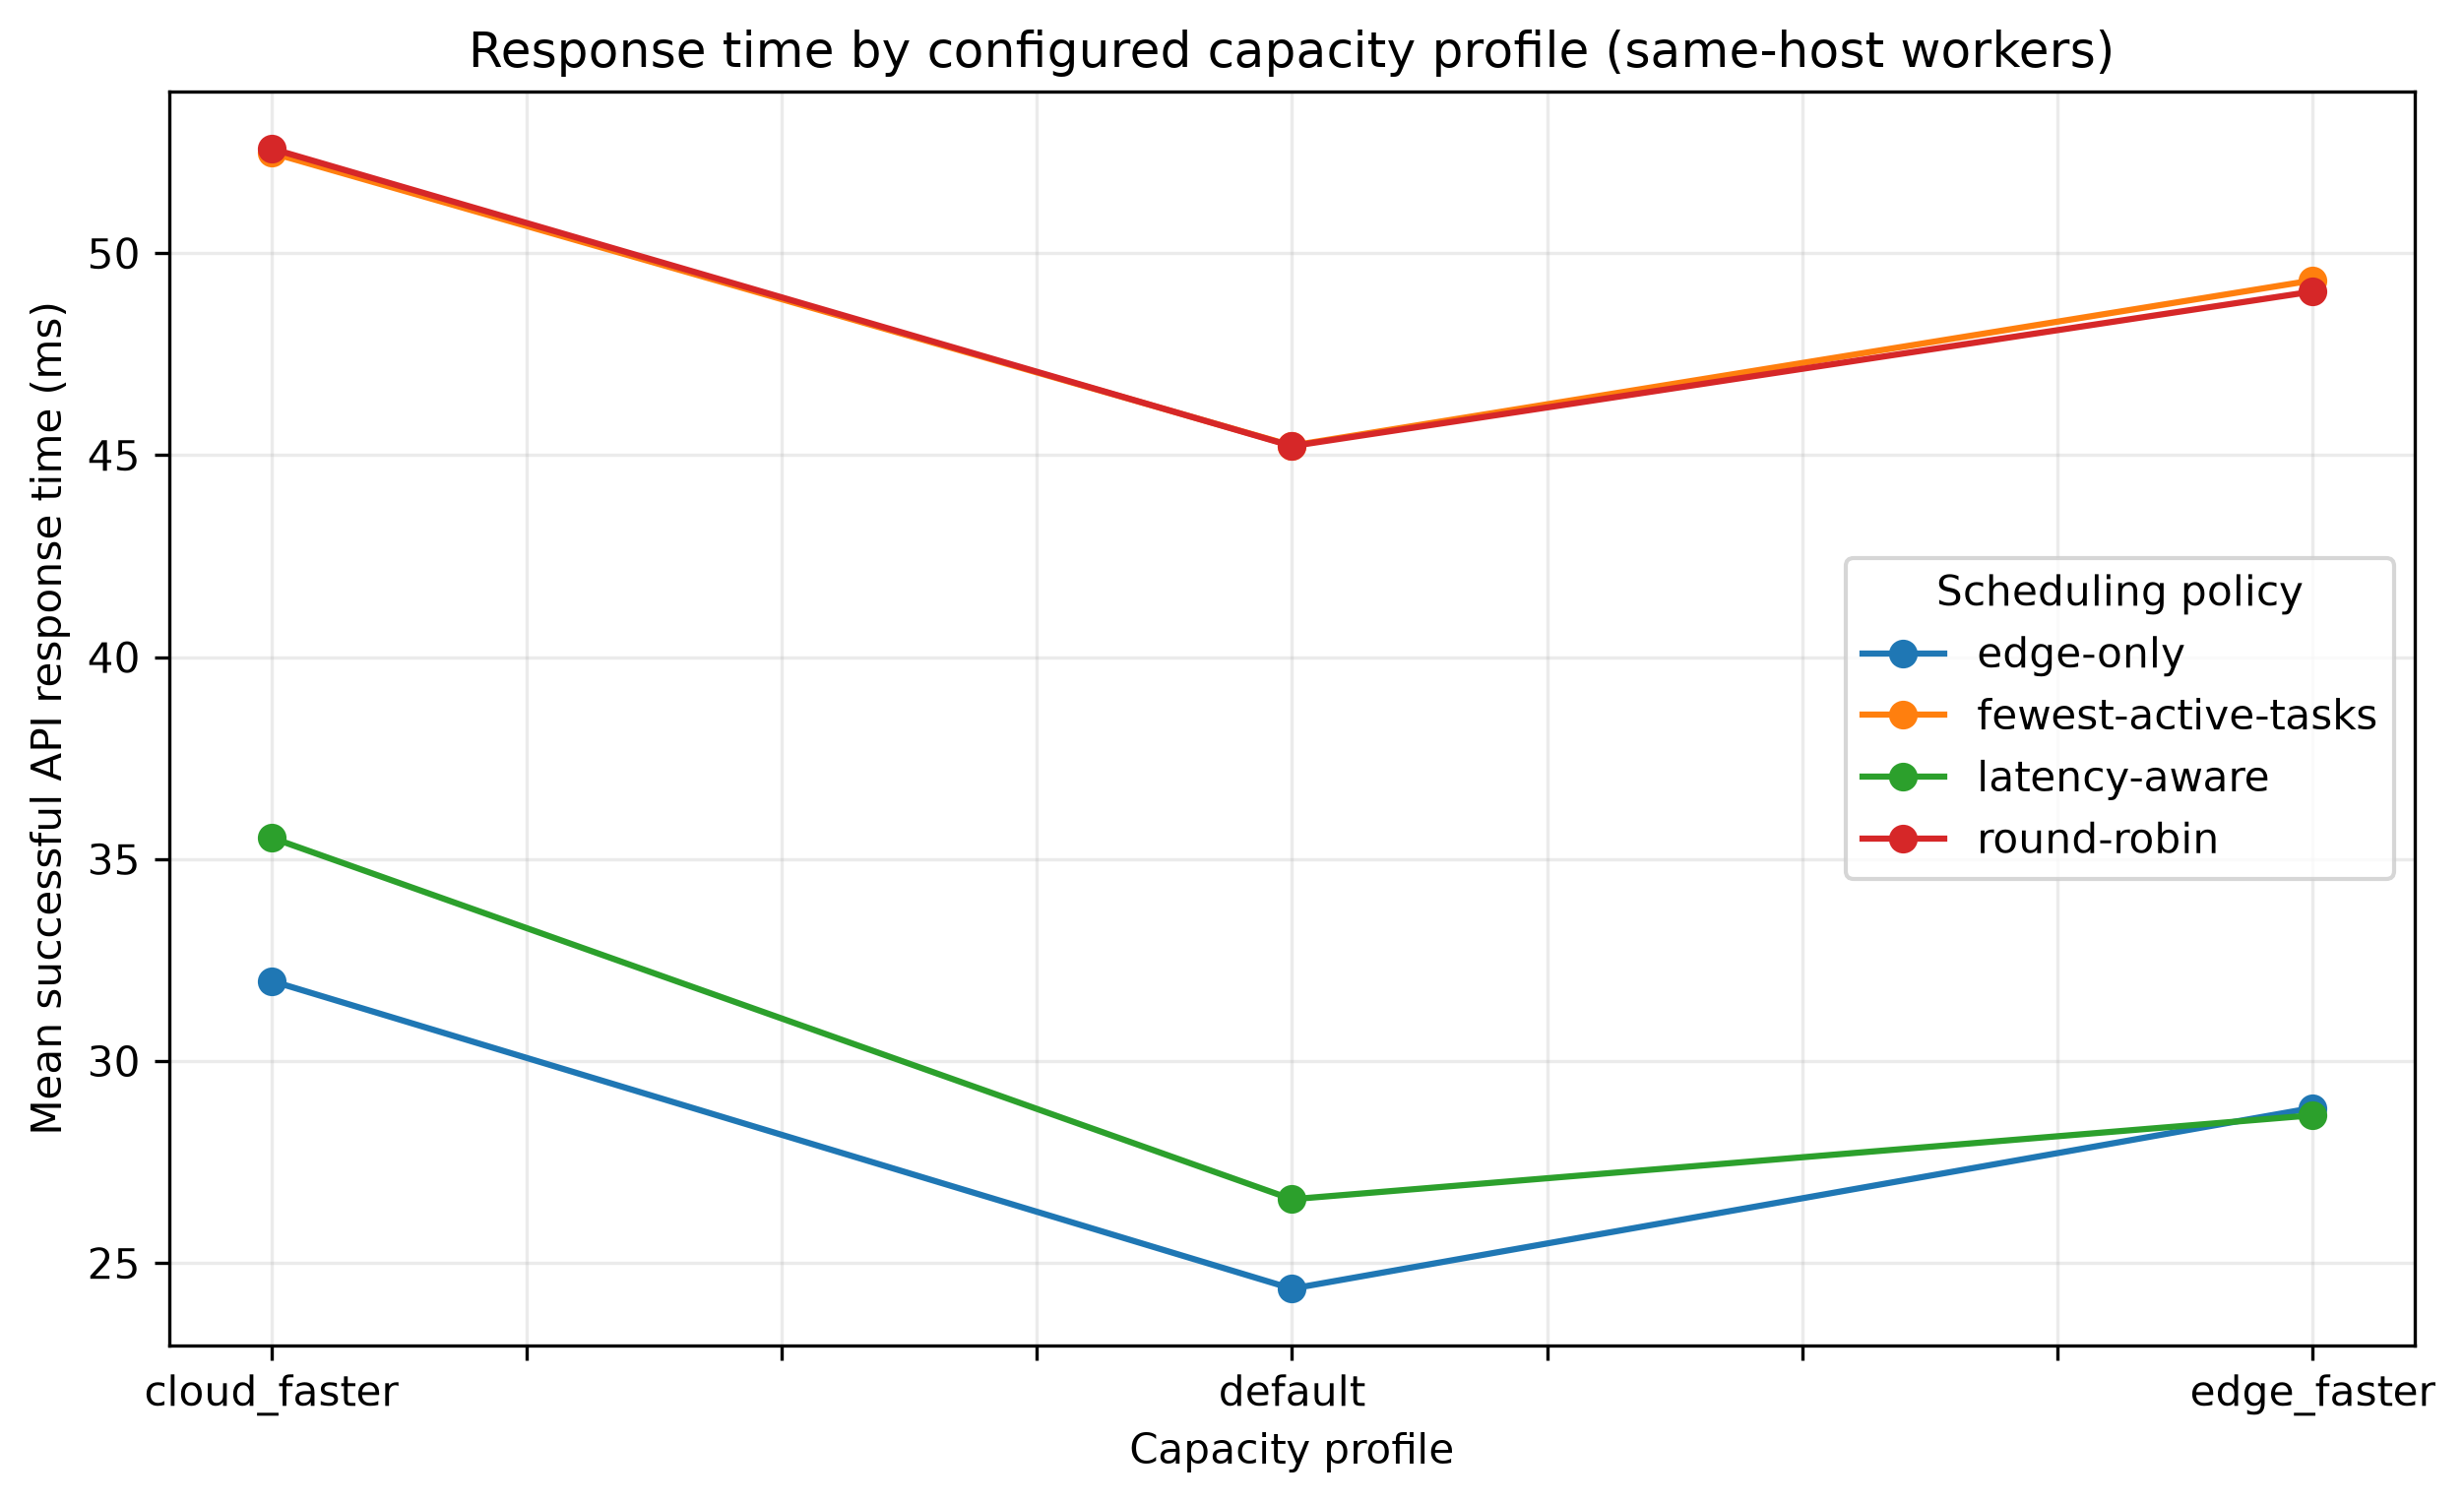

In [12]:
display(Image(filename=str(BENCHMARK_RESULTS / 'graphs' / 'performance_by_capacity.png')))


In [8]:
worker_counts = tasks.groupby(['algorithm', 'worker']).size().unstack(fill_value=0)
worker_counts


worker,cloud-1,edge-1,edge-2
algorithm,,,
edge-only,0,18000,0
fewest-active-tasks,5761,6120,6119
latency-aware,2283,14548,1169
round-robin,5760,6120,6120


In [7]:
paired_path = BENCHMARK_RESULTS / 'graphs' / 'paired_matrix_comparisons.csv'
if paired_path.exists():
    paired = pd.read_csv(paired_path)
    display(paired.sort_values(['baseline', 'networkProfile', 'capacityProfile']))
else:
    print('Paired comparison table is missing. Run research/experiments/generate_graphs.py first.')


Paired comparison table is missing. Run research/experiments/generate_graphs.py first.
